# **Detector de Fraudes do Cartão de Crédito**

Projeto de classificação binária para identificar fraudes em transações de cartão de crédito. A fraude é um evento raro (cerca de 0,17% das transações), então a **acurácia engana** e a avaliação foca na classe de fraude: **recall** (quantas fraudes reais foram encontradas), **precisão** (quantos dos alertas eram fraude de verdade) e **F1** (equilíbrio entre os dois).

O notebook segue este caminho: explorar os dados, prepará-los, treinar e comparar três modelos, avaliar com curvas ROC e de precisão e recall, ajustar hiperparâmetros e limiar de decisão e, por fim, explicar o que levou o modelo a marcar uma transação como fraude (importância das variáveis e SHAP).

---
# 1. Instalação, Importação das Bibliotecas e Leitura da Base de Dados

A base é lida diretamente pelo link, sem baixar o arquivo. A primeira célula instala o `shap`, que não vem instalado por padrão no Google Colab.

In [ ]:
!pip install -q shap

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    recall_score,
    precision_score,
    f1_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from xgboost import XGBClassifier

URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(URL)

print(df.head())
print("\nProporção das Classes:")
print(df["Class"].value_counts(normalize=True))

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

**Leitura do resultado:** a classe 0 (normal) tem 99,83% das transações e a classe 1 (fraude) apenas 0,17%. Um modelo que respondesse "não é fraude" para tudo acertaria cerca de 99,83% e não encontraria nenhuma fraude. Por isso, daqui em diante, os modelos são comparados por recall, precisão e F1 **da classe de fraude**, e não pela acurácia.

As variáveis `V1` a `V28` foram transformadas por PCA para proteger a privacidade dos clientes, então não têm significado direto de negócio. `Time` marca o momento da transação e `Amount` o valor.

---
# 2. Preparação dos Dados

* **`Amount_log = np.log1p(Amount)`:** o valor das transações é muito assimétrico (muitas compras pequenas e poucas muito grandes). O logaritmo reduz essa assimetria. A coluna `Amount` original é removida para não manter duas versões da mesma informação.
* **Divisão 80/20 com `stratify=y`:** mantém a proporção de fraudes (cerca de 0,17%) no treino e no teste. Sem isso, o teste poderia ficar com poucas fraudes ou nenhuma. O teste tem 98 fraudes em 56.962 transações.
* **Padronização:** o `StandardScaler` será aplicado **dentro de um `Pipeline`** (próxima seção), para que seja ajustado só com os dados de treino e não vaze informação do teste.

In [ ]:
# Cria o log do valor e separa X e y
df["Amount_log"] = np.log1p(df["Amount"])
X = df.drop(columns=["Class", "Amount"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

---
# 3. Treinamento e Comparação dos Modelos

Três modelos, todos em um `Pipeline` com `StandardScaler`, com o desbalanceamento tratado por pesos de classe:

* **Regressão Logística** (baseline), com `class_weight="balanced"`.
* **Random Forest**, com `class_weight="balanced"`.
* **XGBoost**, com `scale_pos_weight` igual à razão entre transações normais e fraudes no treino.

In [29]:
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", RandomForestClassifier(
            n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42
        )),
    ]),
    "XGBoost": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", XGBClassifier(
            n_estimators=150,
            learning_rate=0.1,
            max_depth=5,
            scale_pos_weight=peso_fraude,
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42,
        )),
    ]),
}

for nome, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    print(f"=== {nome} ===")
    print(classification_report(y_test, y_pred, digits=4))

=== Regressão Logística ===
              precision    recall  f1-score   support

           0     0.9999    0.9753    0.9874     56864
           1     0.0603    0.9184    0.1131        98

    accuracy                         0.9752     56962
   macro avg     0.5301    0.9468    0.5503     56962
weighted avg     0.9982    0.9752    0.9859     56962

=== Random Forest ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9605    0.7449    0.8391        98

    accuracy                         0.9995     56962
   macro avg     0.9800    0.8724    0.9194     56962
weighted avg     0.9995    0.9995    0.9995     56962

=== XGBoost ===
              precision    recall  f1-score   support

           0     0.9997    0.9995    0.9996     56864
           1     0.7387    0.8367    0.7847        98

    accuracy                         0.9992     56962
   macro avg     0.8692    0.9181    0.8921     56962
weighted

**Leitura do resultado (classe de fraude, limiar 0,5):**

| Modelo | Recall | Precisão | F1 |
|---|---|---|---|
| Regressão Logística | 0,9184 | 0,0603 | 0,1131 |
| Random Forest | 0,7449 | 0,9605 | 0,8391 |
| XGBoost | 0,8367 | 0,7387 | 0,7847 |

* A **regressão logística** encontra cerca de 90 das 98 fraudes, mas com precisão de 6%: são cerca de 1.400 alarmes falsos. Tem 97,5% de acurácia, o que mostra como a acurácia esconde o problema. Na prática, seria inviável.
* O **Random Forest** tem o melhor F1 e poucos alarmes falsos (cerca de 3), mas deixa passar cerca de 1 em cada 4 fraudes.
* O **XGBoost** fica no meio: encontra mais fraudes que o Random Forest, ao custo de mais alarmes falsos (cerca de 29).

Com apenas 98 fraudes no teste, cada fraude vale cerca de 1 ponto percentual de recall, então as diferenças entre modelos são ruidosas.

---
# 4. Curvas ROC e Precision-Recall

Comparação visual dos três modelos. Em dados desbalanceados, a curva de precisão e recall é mais informativa que a ROC, porque a ROC usa a taxa de falsos positivos, que fica pequena quando há muitas transações normais.

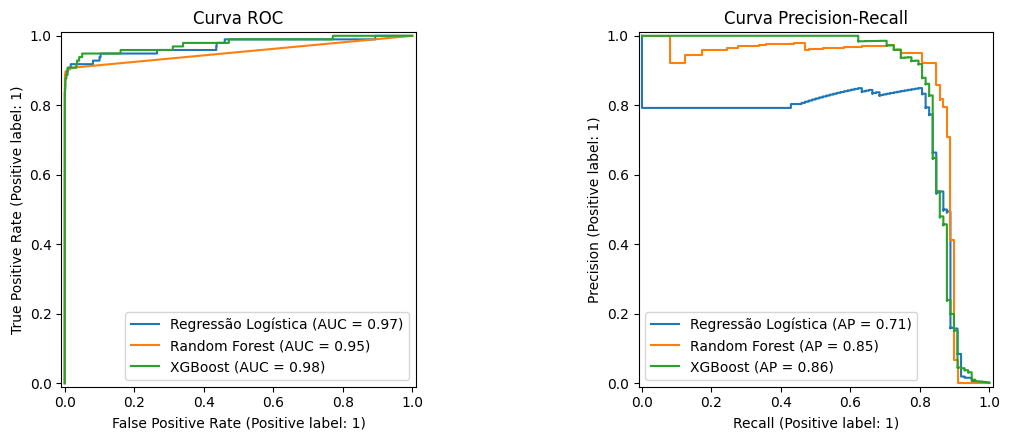

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for nome, pipe in modelos.items():
    probs = pipe.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, probs, name=nome, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, probs, name=nome, ax=ax2)

ax1.set_title("Curva ROC")
ax2.set_title("Curva Precision-Recall")
plt.tight_layout()
plt.show()

**Leitura do resultado:**

| Modelo | AUC (ROC) | Average Precision (PR) |
|---|---|---|
| Regressão Logística | 0,97 | 0,71 |
| Random Forest | 0,95 | 0,85 |
| XGBoost | 0,98 | 0,86 |

* Na **ROC**, os três modelos parecem equivalentes, e a regressão logística (com cerca de 1.400 alarmes falsos) chega a ter AUC igual à do XGBoost. É o efeito do desbalanceamento: a curva esconde o custo dos falsos positivos.
* Na **curva de precisão e recall**, a diferença aparece: a regressão logística fica bem abaixo (AP 0,71), e o Random Forest e o XGBoost ficam próximos (0,85 e 0,86).
* Por isso, a curva de precisão e recall é a leitura principal neste problema.

---
# 5. GridSearchCV e Ajuste de Limiar

Busca dos melhores parâmetros do Random Forest no `Pipeline`, com `scoring="recall"` (como pede o desafio), e comparação do impacto de baixar o limiar de decisão de 0,5 para 0,3 no recall, na precisão e no F1 da fraude. A busca foi reduzida (4 combinações, 3 dobras) por causa do tempo de execução no Colab.

In [31]:
pipe_rf = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        n_jobs=1,
        random_state=42,
    )),
])

param_grid = {
    "modelo__n_estimators": [50, 100],
    "modelo__max_depth": [8, 12],
}

grid = GridSearchCV(
    pipe_rf,
    param_grid,
    scoring="recall",
    cv=3,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

melhor_modelo = grid.best_estimator_
print("Melhores parâmetros:", grid.best_params_)

probs_teste = melhor_modelo.predict_proba(X_test)[:, 1]

for limiar in [0.5, 0.3]:
    preds = (probs_teste >= limiar).astype(int)
    print(
        f"Limiar {limiar:.1f} -> "
        f"Recall: {recall_score(y_test, preds):.4f} | "
        f"Precisão: {precision_score(y_test, preds):.4f} | "
        f"F1: {f1_score(y_test, preds):.4f}"
    )

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhores parâmetros: {'modelo__max_depth': 8, 'modelo__n_estimators': 50}
Limiar 0.5 -> Recall: 0.8469 | Precisão: 0.6336 | F1: 0.7249
Limiar 0.3 -> Recall: 0.8878 | Precisão: 0.3425 | F1: 0.4943


**Leitura do resultado:**

| Modelo / limiar | Recall | Precisão | F1 |
|---|---|---|---|
| Random Forest padrão (0,5) | 0,7449 | 0,9605 | 0,8391 |
| Random Forest ajustado (0,5) | 0,8469 | 0,6336 | 0,7249 |
| Random Forest ajustado (0,3) | 0,8878 | 0,3425 | 0,4943 |

* **Otimizar só o recall piorou o modelo.** A busca escolheu `max_depth=8` e `n_estimators=50`, árvores mais rasas e mais permissivas. O recall subiu cerca de 10 pontos percentuais, mas a precisão caiu cerca de 33 pontos e o F1 caiu de 0,839 para 0,725. Em problemas desbalanceados, `f1` ou `average_precision` tendem a ser critérios mais estáveis que o recall isolado.
* **Baixar o limiar para 0,3** capturou cerca de 4 fraudes a mais (de ~83 para ~87 entre as 98), mas gerou cerca de 119 alarmes falsos a mais (de ~48 para ~167): uns 30 alarmes falsos para cada fraude extra.

**Limiar escolhido: 0,5.** O ganho de recall do 0,3 é pequeno perto da queda de precisão e de F1. Em um sistema real, cada alarme falso é um cliente legítimo bloqueado ou um caso para a equipe de análise revisar.

**Limitação:** a comparação de limiares foi feita no próprio conjunto de teste. O ideal é escolher o limiar por validação cruzada no treino (por exemplo, com `cross_val_predict`) e usar o teste só na avaliação final.

---
# 6. Importância das Variáveis e SHAP

Lista as variáveis mais relevantes segundo o Random Forest ajustado e gera o gráfico de resumo do SHAP (sobre o **XGBoost**, em uma amostra aleatória de 2.000 transações do teste) para mostrar como cada variável puxa a previsão para fraude ou para normal.

As 10 Variáveis mais Importantes:
V14    0.274135
V4     0.104594
V10    0.104284
V17    0.098337
V3     0.089585
V12    0.074179
V16    0.043891
V7     0.031121
V2     0.023770
V9     0.018621
dtype: float64


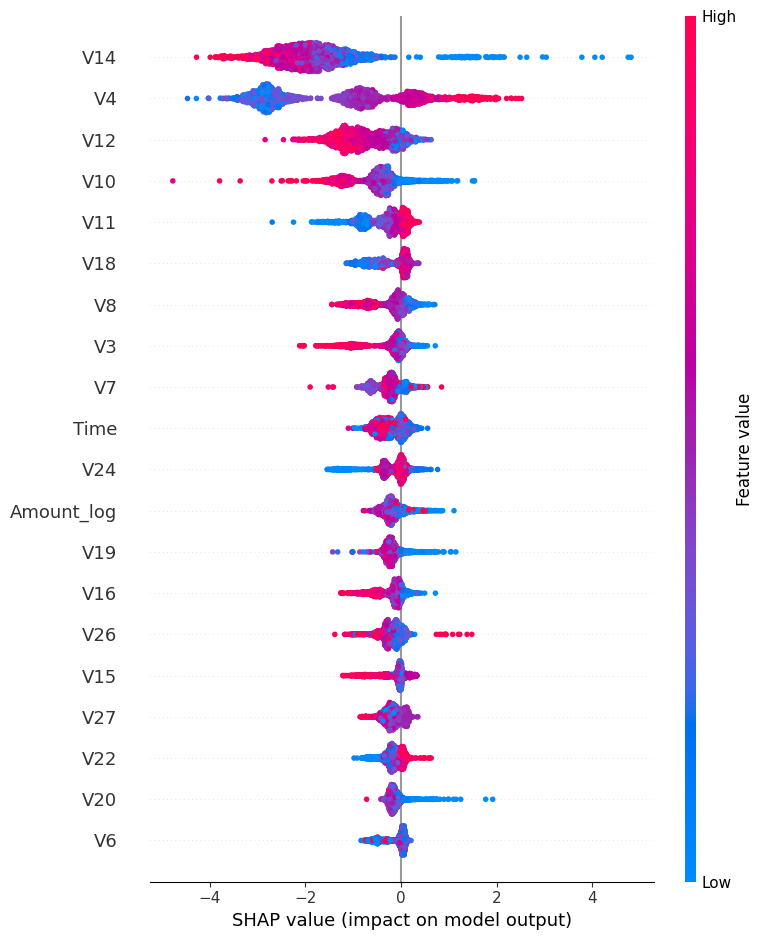

In [32]:
rf_treinado = melhor_modelo.named_steps["modelo"]
importancias = pd.Series(rf_treinado.feature_importances_, index=X.columns).sort_values(ascending=False)
print("As 10 Variáveis mais Importantes:")
print(importancias.head(10))

X_test_scaled = melhor_modelo.named_steps["scaler"].transform(X_test)
X_amostra = pd.DataFrame(X_test_scaled, columns=X.columns).sample(n=2000, random_state=42)

xgb_modelo = modelos["XGBoost"].named_steps["modelo"]
explainer = shap.TreeExplainer(xgb_modelo)
shap_values = explainer.shap_values(X_amostra)

shap.summary_plot(shap_values, X_amostra)

**Como ler o gráfico SHAP:** cada ponto é uma transação. O eixo horizontal está em log-odds: valores positivos empurram a previsão para fraude e negativos, para normal. A cor indica o valor da variável (vermelho = alto, azul = baixo).

* **`V14`** é a que mais pesa: valores **baixos** empurram para fraude (alguns pontos passam de +4) e valores altos puxam para normal.
* **`V4`** age no sentido oposto: valores **altos** empurram para fraude.
* **`V12`, `V10` e `V3`** seguem o padrão de `V14`: valores baixos aumentam o risco de fraude.
* **`V11`** segue o padrão de `V4`: valores altos aumentam o risco.
* `Amount_log` e `Time` têm efeito pequeno perto das variáveis de PCA.

**Comparação com a importância do Random Forest:** `V14` e `V4` estão no topo nos dois métodos, mas o resto da ordem varia (por exemplo, `V17` é importante no Random Forest e nem aparece entre as 20 primeiras do SHAP). São modelos diferentes e medidas diferentes (redução de impureza versus contribuição para a previsão).

**Cuidados:** a maior parte dos pontos tem SHAP negativo porque a amostra tem poucas fraudes (cerca de 3 a 4 em 2.000 transações). Além disso, `V1` a `V28` vêm de PCA e são anônimas: o sinal é útil para o modelo, mas não tem significado direto de negócio.

---
# 7. Conclusão e Próximos Passos

* **Métrica:** em fraude, a acurácia engana. A avaliação correta usa recall, precisão e F1 da classe de fraude e a curva de precisão e recall.
* **Modelos:** o Random Forest padrão teve o melhor F1 (0,839) e o XGBoost teve a melhor Average Precision (0,86), com recall maior (0,837) e mais alarmes falsos. A regressão logística tem recall alto, mas precisão inviável (6%).
* **Ajuste:** otimizar só o recall no `GridSearchCV` piorou o F1, e baixar o limiar para 0,3 trocou poucas fraudes a mais por muitos alarmes falsos. O limiar escolhido foi 0,5.
* **Explicação:** `V14` e `V4` são as variáveis mais influentes nos dois métodos.

**Próximos passos:** escolher o limiar com probabilidades out-of-fold e vários valores (de 0,1 a 0,7); refazer o `GridSearchCV` com `average_precision`; comparar undersampling e oversampling (SMOTE) com o `Pipeline` do `imblearn`; fazer o SHAP com todas as fraudes do teste e explicar uma transação individual (gráfico waterfall); e usar uma matriz de custo financeiro para definir o limiar.